# Liver disease (ILPD): exploratory data analysis

583 patients from north-east Andhra Pradesh, India (13 exact duplicates removed -> 570); 10 attributes from liver function tests.

> Part of the MediAssist CDSS project. Data loading and cleaning live in `ml/src/medml/data.py`, so this notebook and the training pipeline see exactly the same data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from medml.data import load

sns.set_theme(style="whitegrid", palette="crest")
pd.set_option("display.precision", 2)

In [2]:
data = load("liver")
df = data.X.assign(target=data.y)
print(data.source)
print(df.shape)
df.head()

Indian Liver Patient Dataset, ILPD (Ramana & Venkateswarlu, 2012)
(570, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Proteins,Albumin,Albumin_and_Globulin_Ratio,target
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1


## Cleaning applied

In [3]:
for step in data.cleaning_log:
    print("-", step)

- Removed 13 exact duplicate rows so no patient appears in both train and test
- Gender encoded as 0 = female, 1 = male
- Albumin_and_Globulin_Ratio: 4 missing values imputed (median)
- Target remapped from (1 = disease, 2 = healthy) to (1 = disease, 0 = healthy)


## Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,570.0,44.85,16.24,4.0,33.0,45.00,58.00,90.0
Gender,570.0,0.75,0.43,0.0,1.0,1.00,1.00,1.0
Total_Bilirubin,570.0,3.32,6.27,0.4,0.8,1.00,2.60,75.0
Direct_Bilirubin,570.0,1.50,2.83,0.1,0.2,0.30,1.30,19.7
Alkaline_Phosphotase,570.0,291.75,245.29,63.0,176.0,208.00,298.00,2110.0
Alamine_Aminotransferase,570.0,79.73,181.47,10.0,23.0,35.00,60.00,2000.0
Aspartate_Aminotransferase,570.0,109.38,290.88,10.0,25.0,41.00,86.75,4929.0
Total_Proteins,570.0,6.50,1.09,2.7,5.8,6.60,7.20,9.6
Albumin,570.0,3.15,0.80,0.9,2.6,3.10,3.80,5.5
Albumin_and_Globulin_Ratio,566.0,0.95,0.32,0.3,0.7,0.95,1.10,2.8


## Class balance and missing values

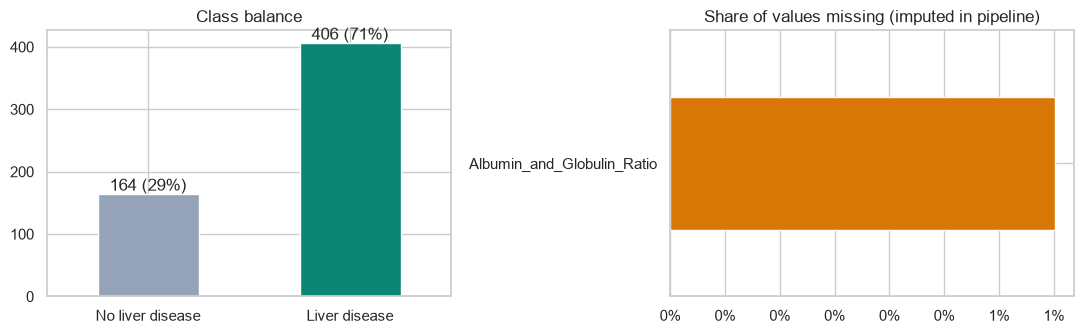

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
balance = pd.Series(data.class_balance())
balance.plot.bar(ax=axes[0], color=["#94a3b8", "#0d8574"], rot=0)
axes[0].set_title("Class balance")
for i, v in enumerate(balance):
    axes[0].text(i, v, f"{v} ({v / balance.sum():.0%})", ha="center", va="bottom")
missing = data.X.isna().mean().sort_values(ascending=False)
missing[missing > 0].plot.barh(ax=axes[1], color="#d97706")
axes[1].set_title("Share of values missing (imputed in pipeline)")
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout()

## Feature distributions by outcome

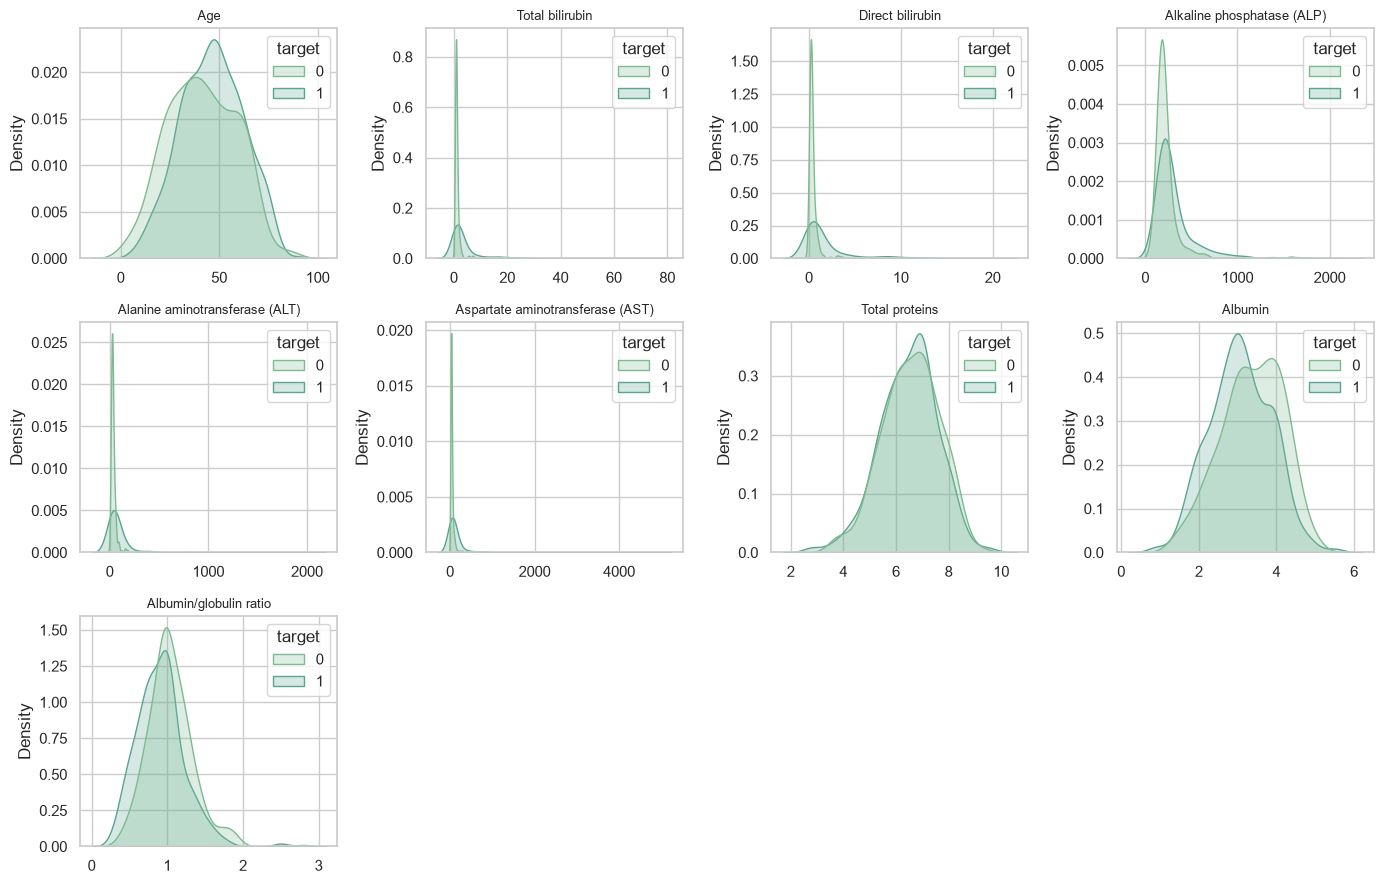

In [6]:
numeric = [f.name for f in data.features if f.kind == "numeric"]
labels = {f.name: f.label for f in data.features}
cols = 4
rows = int(np.ceil(len(numeric) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3 * rows))
for ax, col in zip(axes.flat, numeric):
    sns.kdeplot(
        data=df, x=col, hue="target", common_norm=False, fill=True, ax=ax, warn_singular=False
    )
    ax.set_title(labels[col], fontsize=9)
    ax.set_xlabel("")
for ax in list(axes.flat)[len(numeric) :]:
    ax.remove()
plt.tight_layout()

## Correlation with the outcome

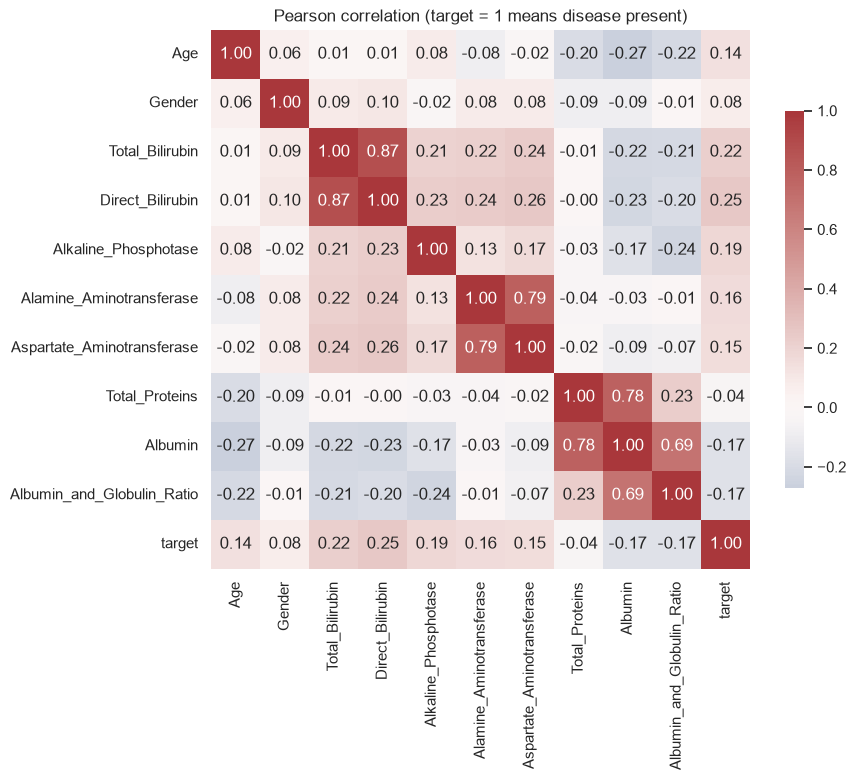

Direct_Bilirubin              0.25
Total_Bilirubin               0.22
Alkaline_Phosphotase          0.19
Albumin_and_Globulin_Ratio   -0.17
Albumin                      -0.17
Alamine_Aminotransferase      0.16
Aspartate_Aminotransferase    0.15
Age                           0.14
Gender                        0.08
Total_Proteins               -0.04
Name: target, dtype: float64

In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7}
)
plt.title("Pearson correlation (target = 1 means disease present)")
plt.show()
corr["target"].drop("target").sort_values(key=abs, ascending=False)

## Observations

- **Duplicates removed** before any split, otherwise identical patients could sit in both train and test sets.
- **Skewed enzyme values:** bilirubin, ALP, ALT and AST have long right tails (some values are 10-50x normal). Decision trees split on thresholds, so they handle this without a log transform, which is one reason trees suit lab data.
- Total and direct bilirubin are highly correlated (they measure overlapping quantities); the tree usually uses only one of them.
- **Imbalance (71% disease) and 76% male:** recorded as limitations in the model card. This dataset is known to be hard; published results are typically around 70% accuracy.